In [5]:
from pathlib import Path
import pandas as pd
import json
import matplotlib.pyplot as plt

In [3]:
def get_cardinality_distribution(query_results_path: Path) -> pd.DataFrame:
    with open(query_results_path, 'r') as f:
        query_results = json.load(f)
    
    cardinalities = [result['y'] for result in query_results]
    distribution = pd.Series(cardinalities).value_counts().sort_index()
    
    return distribution

In [4]:

star_queries_path = Path("/Users/lukas/Workspace/Uni/BachelorsThesis/FICE/data/fb237_v4_ind_star_queries/raw/59731859?private_link=953281688dbdb230c09d")
path_queries_path = Path("/Users/lukas/Workspace/Uni/BachelorsThesis/FICE/data/fb237_v4_ind_path_queries/raw/59900708?private_link=103743702bc11e9b4672")


In [6]:
# Load cardinality distributions
star_distribution = get_cardinality_distribution(star_queries_path)
path_distribution = get_cardinality_distribution(path_queries_path)

print(f"Star queries: {len(star_distribution)} unique cardinalities")
print(f"Path queries: {len(path_distribution)} unique cardinalities")

Star queries: 6021 unique cardinalities
Path queries: 5986 unique cardinalities


In [7]:
# Extract cardinality values for histogram
with open(star_queries_path, 'r') as f:
    star_queries = json.load(f)
star_cardinalities = [result['y'] for result in star_queries]

with open(path_queries_path, 'r') as f:
    path_queries = json.load(f)
path_cardinalities = [result['y'] for result in path_queries]

print(f"Total star queries: {len(star_cardinalities)}")
print(f"Total path queries: {len(path_cardinalities)}")

Total star queries: 41654
Total path queries: 21356


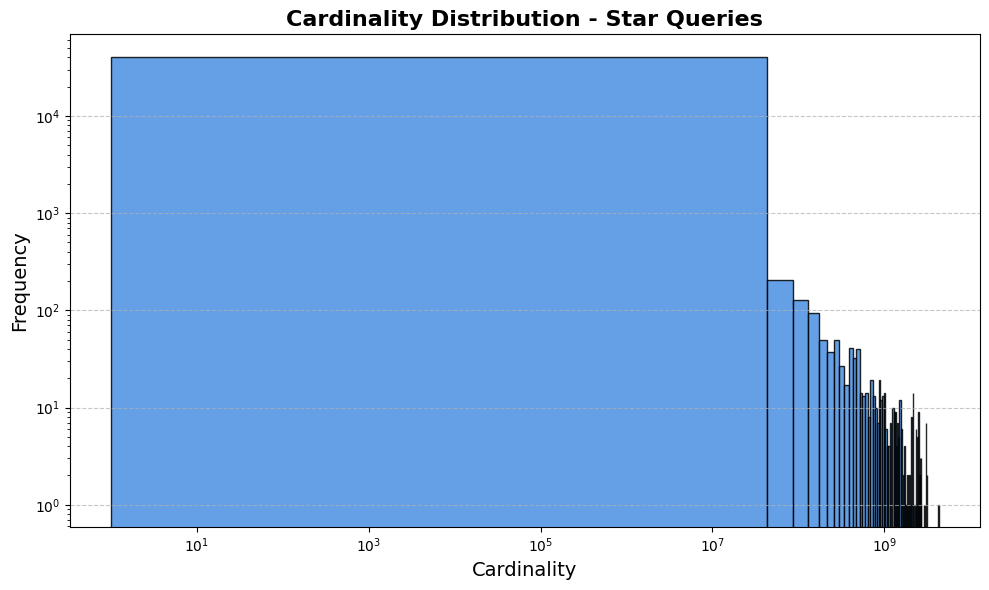

In [8]:
# Create histogram for star queries
plt.figure(figsize=(10, 6))
plt.hist(star_cardinalities, bins=100, color='#4a90e2', edgecolor='black', alpha=0.85)
plt.xlabel('Cardinality', fontsize=14)
plt.ylabel('Frequency', fontsize=14)
plt.title('Cardinality Distribution - Star Queries', fontsize=16, fontweight='bold')
plt.xscale('log')
plt.yscale('log')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

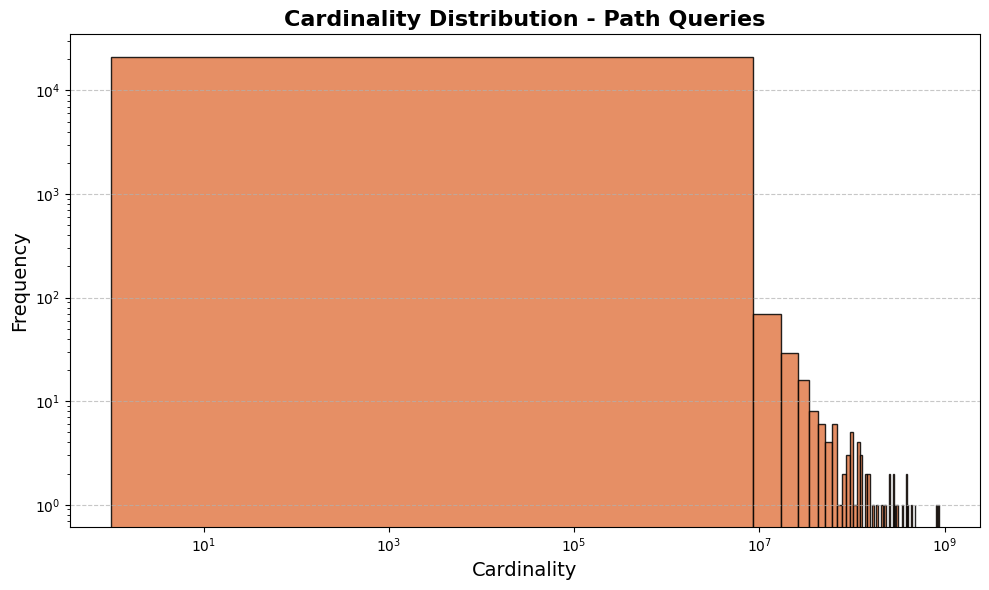

In [9]:
# Create histogram for path queries
plt.figure(figsize=(10, 6))
plt.hist(path_cardinalities, bins=100, color='#e27c4a', edgecolor='black', alpha=0.85)
plt.xlabel('Cardinality', fontsize=14)
plt.ylabel('Frequency', fontsize=14)
plt.title('Cardinality Distribution - Path Queries', fontsize=16, fontweight='bold')
plt.xscale('log')
plt.yscale('log')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()